### Generalized Klotski — Lab 4

Solve every puzzle in `klotski_problems.txt` by searching for a path.

| From Lecture | Klotski |
|---|---|
| state *s* | the board: a tuple of rows, each cell a piece name or `.` |
| initial state | the board in the file |
| actions A(s) | slide one piece by one cell into empty cells |
| result R(s, a) | the board after that slide |
| goal test G(s) | the target piece covers the exit cells on the bottom edge |
| path cost C(P) | number of moves (each move costs 1, so uniform cost) |

In [1]:
import heapq
import itertools
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

### 1. Parsing from `klotski_problems.txt`

Each problem in the file has an id, the exit columns, the target piece and the board between two `=========` lines.
The board itself becomes the **state**: a tuple of tuple.

In [2]:
def parse_problems(path):
    # Read the benchmark file -> {id: problem dict}.
    problems, current, board, inside = {}, None, [], False
    for line in Path(path).read_text().splitlines():
        line = line.strip()
        if line == "=========":                     # opens or closes a board
            if inside:
                current["start"] = tuple(tuple(row) for row in board)
                problems[current["id"]] = current
                board = []
            inside = not inside
        elif inside:
            board.append(line.split())              # one token per cell
        elif line and not line.startswith("#"):
            word, *values = line.split()
            if word == "problem":
                current = {"id": values[0]}
            elif word == "exit":                    # "exit bottom 1 2"
                current["exit_cols"] = [int(v) for v in values[1:]]
            elif word == "target":
                current["target"] = values[0]
    return problems


problems = parse_problems("klotski_problems.txt")
for pid, p in problems.items():
    rows, cols = len(p["start"]), len(p["start"][0])
    print(f"{pid}: {rows}x{cols} board, target {p['target']}, exit under columns {p['exit_cols']}")

p01: 3x3 board, target A, exit under columns [1]
p02: 4x4 board, target A, exit under columns [1, 2]
p03: 4x4 board, target A, exit under columns [1, 2]
p04: 5x4 board, target A, exit under columns [1, 2]
p05: 5x4 board, target A, exit under columns [1, 2]
p06: 4x4 board, target A, exit under columns [1, 2]


### 2. Pieces and drawing

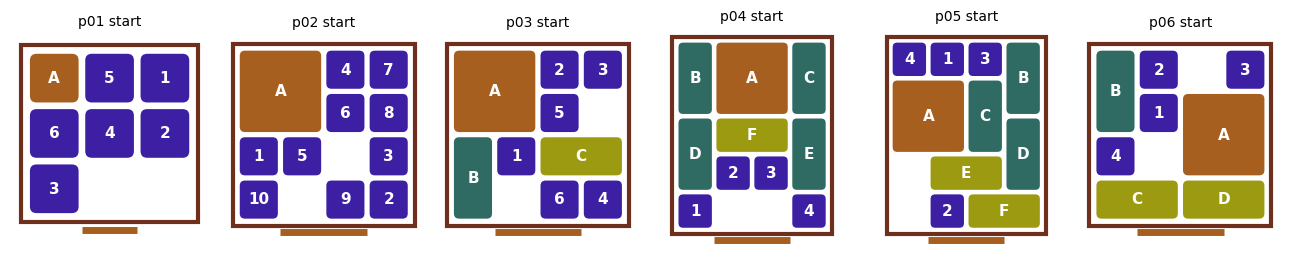

In [3]:
def pieces_of(state):
    # {piece name: list of its (row, col) cells}
    pieces = {}
    for r, row in enumerate(state):
        for c, name in enumerate(row):
            if name != ".":
                pieces.setdefault(name, []).append((r, c))
    return pieces


def piece_box(cells):
    # Top-left corner, height and width of a rectangular piece.
    top, left = min(r for r, _ in cells), min(c for _, c in cells)
    height = max(r for r, _ in cells) - top + 1
    width = max(c for _, c in cells) - left + 1
    return top, left, height, width


COLORS = {"target": "#a65f1f", "1x1": "#3d1fa3", "vertical": "#2f6b63", "horizontal": "#9c9a10"}

def draw_board(state, problem, ax, title=None, highlight=None):
    rows, cols = len(state), len(state[0])
    ax.add_patch(patches.Rectangle((-0.1, -0.1), cols + 0.2, rows + 0.2, fill=False, lw=3, ec="#6e2f1c"))
    exit_cols = problem["exit_cols"]
    ax.plot([exit_cols[0], exit_cols[-1] + 1], [rows + 0.25] * 2, lw=5, color="#a65f1f", solid_capstyle="butt")
    for name, cells in pieces_of(state).items():
        top, left, h, w = piece_box(cells)
        kind = ("target" if name == problem["target"] else
                "1x1" if h == w == 1 else "vertical" if h > w else "horizontal")
        ax.add_patch(patches.FancyBboxPatch((left + 0.06, top + 0.06), w - 0.12, h - 0.12,
                     boxstyle="round,pad=0,rounding_size=0.12", fc=COLORS[kind],
                     ec="black" if name == highlight else "none", lw=2.5))
        ax.text(left + w / 2, top + h / 2, name, ha="center", va="center", color="white",
                fontsize=11, fontweight="bold")
    ax.set_xlim(-0.3, cols + 0.3)
    ax.set_ylim(rows + 0.5, -0.3)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)


def draw_boards(boards, problem, titles, per_row=6, highlights=None):
    n = len(boards)
    rows = (n + per_row - 1) // per_row
    fig, axes = plt.subplots(rows, per_row, figsize=(2.1 * per_row, 2.4 * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        if i < n:
            draw_board(boards[i], problem, ax, titles[i], highlights[i] if highlights else None)
        else:
            ax.axis("off")
    plt.tight_layout()
    plt.show()


fig, axes = plt.subplots(1, len(problems), figsize=(13, 2.6))
for ax, (pid, p) in zip(axes, problems.items()):
    draw_board(p["start"], p, ax, f"{pid} start")
plt.tight_layout()
plt.show()

### 3. Goal test G(s)

The target must cover the exit cells: the bottom row(s) on the exit columns.
The target's height (number of rows) tells how many rows to check, so the same function works for both 1×1 target (p01) and 2×2 target.

In [4]:
def goal_test(state, problem):
    target, exit_cols = problem["target"], problem["exit_cols"]
    rows = len(state)
    height = sum(1 for row in state if target in row)
    return all(state[r][c] == target
               for r in range(rows - height, rows)
               for c in exit_cols)


print("p01 start is a goal?", goal_test(problems["p01"]["start"], problems["p01"]))

p01 start is a goal? False


### 4. Actions A(s) and result R(s, a)

For every piece and every direction, check each cell the piece would land on:
it must be inside the board and empty or part of the same piece (this rule lets a piece slide into its own old cells).
If the move is legal, build the new board in two passes: first lift the piece (write `.`), then put it down shifted.

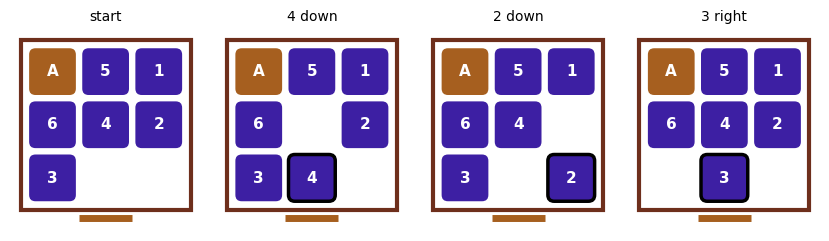

In [5]:
MOVES = {"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1)}

def successors(state):
    # Yield (action, new_state) for every legal move
    rows, cols = len(state), len(state[0])
    for name, cells in pieces_of(state).items():
        for direction, (dr, dc) in MOVES.items():
            legal = all(0 <= r + dr < rows and 0 <= c + dc < cols
                        and state[r + dr][c + dc] in (".", name)
                        for r, c in cells)
            if not legal:
                continue
            grid = [list(row) for row in state]
            for r, c in cells:                      # lift the piece
                grid[r][c] = "."
            for r, c in cells:                      # put it down shifted
                grid[r + dr][c + dc] = name
            yield f"{name} {direction}", tuple(tuple(row) for row in grid)


p01 = problems["p01"]
moves = list(successors(p01["start"]))
draw_boards([p01["start"]] + [s for _, s in moves], p01,
            ["start"] + [a for a, _ in moves], per_row=4,
            highlights=[None] + [a.split()[0] for a, _ in moves])

### 5. Avoiding duplicate boards: key

Two boards that differ only by swapping two identical pieces are the same puzzle position, so the search should count them once.

So `key` replaces each name with the piece's shape (`1x1`, `2x1`, `1x2`) and keeps the target's name.

The search uses the key to decide "seen before?", but keeps a real board (with names) for each key.

In [ ]:
def shape_labels(state, target):
    # Each non-target piece name -> its shape as rows x cols.
    labels = {}
    for name, cells in pieces_of(state).items():
        if name != target:
            _, _, h, w = piece_box(cells)
            labels[name] = f"{h}x{w}"
    return labels


def key(state, labels):
    return tuple(tuple(labels.get(t, t) for t in row) for row in state)


for p in problems.values():
    p["labels"] = shape_labels(p["start"], p["target"])

p03 = problems["p03"]
print("p03 board:")
for row in p03["start"]:
    print("  ", " ".join(f"{t:>3}" for t in row))
print("p03 key:")
for row in key(p03["start"], p03["labels"]):
    print("  ", " ".join(f"{t:>3}" for t in row))

p03 board:
     A   A   2   3
     A   A   5   .
     B   1   C   C
     B   .   6   4
p03 key:
     A   A 1x1 1x1
     A   A 1x1   .
   2x1 1x1 1x2 1x2
   2x1   . 1x1 1x1


### 6. A heuristic for the informed strategies

Build it by relaxing the rules: pretend the target can slide through other pieces.
- It still needs at least its direct distance to the exit position.
- Every other piece sitting on the exit cells must move at least once.

One move shifts one piece by one cell, so this never overestimates the real number of moves and changes by at most 1 per move. That is what A\* needs to return optimal solutions.

In [7]:
def h(state, problem):
    target, exit_cols = problem["target"], problem["exit_cols"]
    top, left, height, _ = piece_box(pieces_of(state)[target])
    goal_top, goal_left = len(state) - height, exit_cols[0]
    distance = abs(goal_top - top) + abs(goal_left - left)
    if distance == 0:
        return 0
    goal_cells = [(r, c) for r in range(goal_top, len(state)) for c in exit_cols]
    blockers = {state[r][c] for r, c in goal_cells} - {".", target}
    return distance + len(blockers)


print("h(p01 start) =", h(p01["start"], p01))
print("h(p02 start) =", h(problems["p02"]["start"], problems["p02"]))

h(p01 start) = 3
h(p02 start) = 5


### 7. Search

One loop for every strategy. The frontier is a priority queue (`heapq`), popped smallest-first.
- Graph search: `closed` holds the keys already expanded, so no board is expanded twice.
- The goal is tested when a board is popped, not when it is generated. That is what makes breadth-first and A\* optimal.
- If a cheaper way to a waiting board is found, its cost and parent are updated and it is pushed again; the old copy is skipped when it comes out (`if k in closed`).
- `parent` remembers how each board was reached; `build_path` walks it back from the goal.

In [8]:
def search(problem, priority):
    # Returns (path, expanded), path = [(action, board), ...] or None if unsolvable.
    labels = problem["labels"]
    start = problem["start"]
    k0 = key(start, labels)
    board = {k0: start}            # key -> a real board with piece names
    cost = {k0: 0}                 # key -> g = moves from the start
    parent = {k0: None}            # key -> (previous key, action)
    tie = itertools.count()        # equal priority -> first in, first out
    frontier = [(priority(0, start), next(tie), k0)]
    closed = set()
    expanded = 0

    while frontier:
        _, _, k = heapq.heappop(frontier)
        if k in closed:                            # stale copy, already expanded
            continue
        state = board[k]
        if goal_test(state, problem):              # test when extracted
            return build_path(parent, board, k), expanded
        closed.add(k)
        expanded += 1
        for action, new_state in successors(state):
            nk = key(new_state, labels)
            g = cost[k] + 1                        # every move costs 1
            if nk in closed:
                continue
            if nk not in cost or g < cost[nk]:     # new board, or a cheaper path to it
                cost[nk], parent[nk], board[nk] = g, (k, action), new_state
                heapq.heappush(frontier, (priority(g, new_state), next(tie), nk))
    return None, expanded                          # frontier empty: no solution


def build_path(parent, board, k):
    path = []
    while parent[k] is not None:
        previous, action = parent[k]
        path.append((action, board[k]))
        k = previous
    return path[::-1]

The four strategies of the lecture are now just four priority functions:

| Strategy | priority | Lecture |
|---|---|---|
| Breadth-first | g (moves so far) |: complete; optimal when all costs are equal (= Dijkstra with unit cost) |
| Depth-first | −g |: deepest first, finds *a* solution, usually a long one |
| Greedy best-first | h |: follows the estimate only, not optimal |
| A\* | g + h |: optimal with an admissible, consistent h |

In [9]:
def strategies(problem):
    return {
        "Breadth-first": lambda g, s: g,
        "Depth-first":   lambda g, s: -g,
        "Greedy":        lambda g, s: h(s, problem),
        "A*":            lambda g, s: g + h(s, problem),
    }

### 8. Levels 1 and 2 with BFS

In [10]:
for pid in ["p01", "p02"]:
    p = problems[pid]
    path, expanded = search(p, strategies(p)["Breadth-first"])
    print(f"{pid}: {len(path)} moves, {expanded} boards expanded")
    print("   " + ", ".join(action for action, _ in path))

p01: 8 moves, 107 boards expanded
   4 down, 5 down, A right, 6 up, 5 left, A down, 4 right, A down
p02: 18 moves, 256 boards expanded
   5 down, 1 right, 1 right, A down, 4 left, 4 left, 6 up, 6 left, 1 up, 1 up, A right, 10 up, 10 up, 5 left, 5 up, 9 left, 9 left, A down


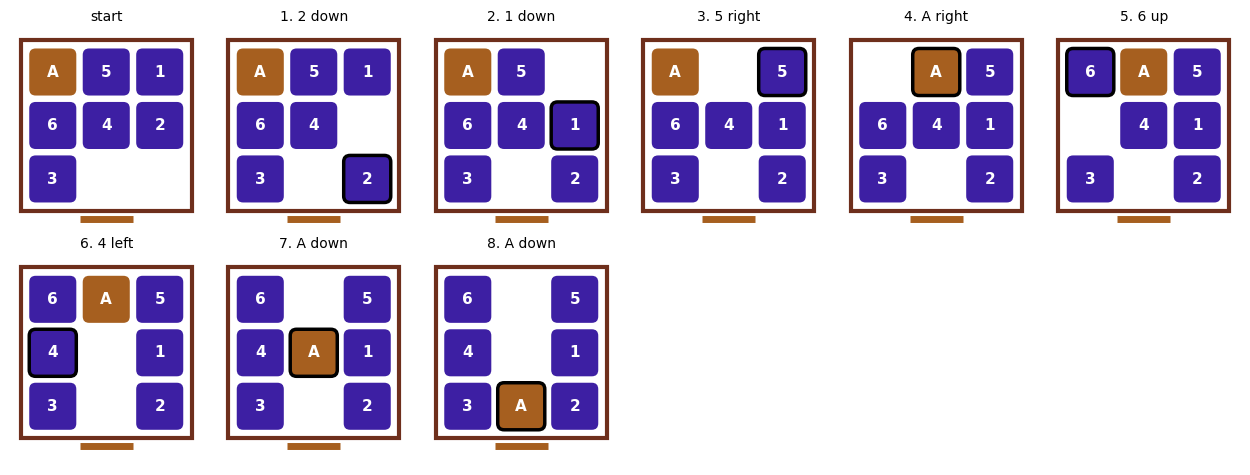

In [11]:
def show_solution(pid, strategy="A*", per_row=6, every=1):
    p = problems[pid]
    path, _ = search(p, strategies(p)[strategy])
    steps = [(None, p["start"])] + path
    picked = [(i, a, s) for i, (a, s) in enumerate(steps) if i % every == 0 or i == len(path)]
    draw_boards([s for _, _, s in picked], p,
                ["start" if a is None else f"{i}. {a}" for i, a, _ in picked],
                per_row=per_row, highlights=[a.split()[0] if a else None for _, a, _ in picked])

show_solution("p01")

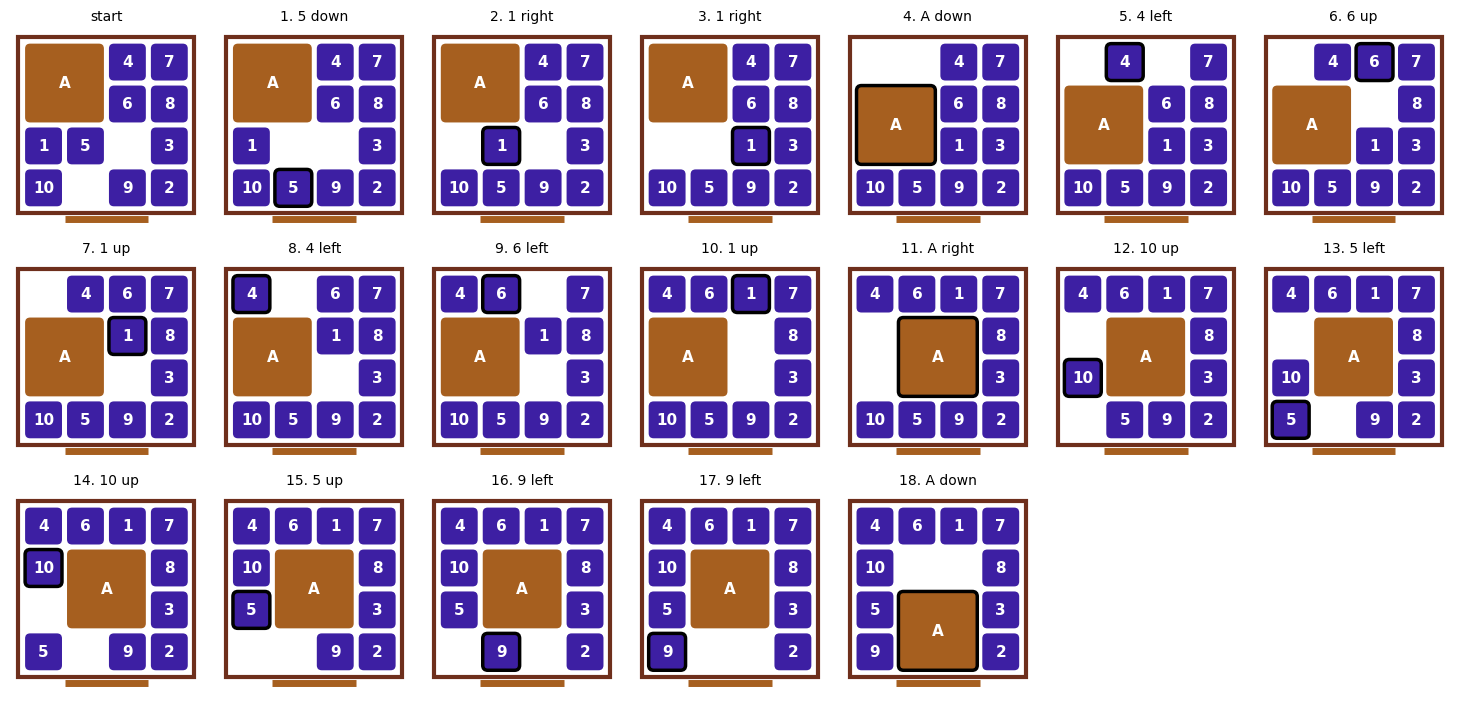

In [12]:
show_solution("p02", per_row=7)

### 9. All six problems, all four strategies

In [13]:
rows = []
for pid, p in problems.items():
    for name, priority in strategies(p).items():
        t0 = time.perf_counter()
        path, expanded = search(p, priority)
        rows.append({"problem": pid, "strategy": name,
                     "moves": len(path) if path is not None else None,
                     "expanded": expanded,
                     "seconds": round(time.perf_counter() - t0, 2)})

results = pd.DataFrame(rows).astype({"moves": "Int64"})
results.pivot(index="problem", columns="strategy", values=["moves", "expanded"])

moves                                  expanded                \
strategy    A* Breadth-first Depth-first Greedy       A* Breadth-first   
problem                                                                  
p01          8             8          51      8       62           107   
p02         18            18          62     18      195           256   
p03         45            45         615     49     2051          2125   
p04        116           116        1101    196    23742         24029   
p05        179           179        6305    308    37304         40114   
p06       <NA>          <NA>        <NA>   <NA>      833           833   

                             
strategy Depth-first Greedy  
problem                      
p01               58      9  
p02               75     55  
p03             1421   1124  
p04             2367   8029  
p05            23979  27739  
p06              833    833

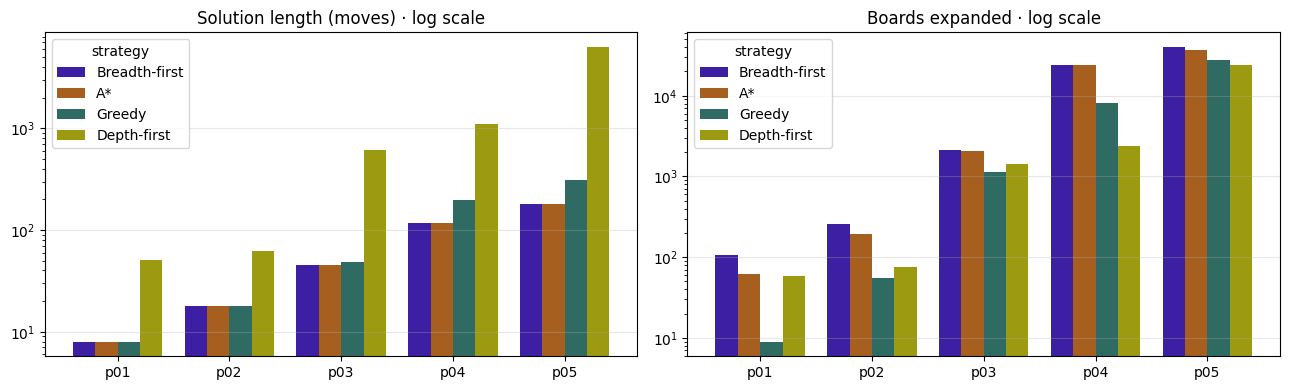

In [14]:
solved = results.dropna(subset=["moves"])
order = ["Breadth-first", "A*", "Greedy", "Depth-first"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in [(ax1, "moves", "Solution length (moves)"), (ax2, "expanded", "Boards expanded")]:
    table = solved.pivot(index="problem", columns="strategy", values=col)[order]
    table.plot.bar(ax=ax, logy=True, rot=0, width=0.8,
                   color=["#3d1fa3", "#a65f1f", "#2f6b63", "#9c9a10"])
    ax.set_title(title + " · log scale")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
path, expanded = search(problems["p06"], strategies(problems["p06"])["Breadth-first"])
print("p06 solution:", path)
print("boards reachable from the start:", expanded)

p06 solution: None
boards reachable from the start: 833
